# Fashion-MNIST Project: Baseline CNN

This notebook starts the project with a simple CNN trained on the original Fashion-MNIST images. First, we will load and inspect the data, then train a baseline model. Later, the team can compare this with a model trained on images containing the artificial corner marker.

**Goal for this first run:** confirm that the data and model work, and record training/validation accuracy and loss. The official test set is kept for the final comparison.


## 1. Import packages and choose a device

A CNN processes each image as a small grid of pixel values. PyTorch provides the model and training tools; torchvision provides Fashion-MNIST.


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Use the same random seed so the data split and initialization are repeatable.
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    mps_backend = getattr(torch.backends, "mps", None)
    if mps_backend is not None and mps_backend.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")

print("Using device:", device)


Using device: cuda


## 2. Load Fashion-MNIST

Fashion-MNIST has 60,000 training images and 10,000 test images. Each image is 28 by 28 pixels and belongs to one of 10 clothing categories. `ToTensor()` turns each image into numbers between 0 and 1, which the CNN can process.


In [ ]:
transform = transforms.ToTensor()

train_all = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform,
)

class_names = train_all.classes
print("Training images:", len(train_all))
print("Test images:", len(test_data))
print("Image shape:", train_all[0][0].shape)
print("Categories:", class_names)


Training images: 60000
Test images: 10000
Image shape: torch.Size([1, 28, 28])
Categories: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 3. Make training and validation sets

We split the 60,000 training images into 54,000 for learning and 6,000 for validation. Validation data helps us check whether the model is improving on images it did not train on. We will save the official 10,000-image test set for the final comparison.


In [ ]:
train_size = 54_000
validation_size = 6_000

train_data, validation_data = random_split(
    train_all,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(seed),
)

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=0)
validation_loader = DataLoader(validation_data, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)

print("Training split:", len(train_data))
print("Validation split:", len(validation_data))


Training split: 54000
Validation split: 6000


## 4. Look at example images

Before training, check that the images and labels look right. This also gives us a visual reference for the later marker experiment.


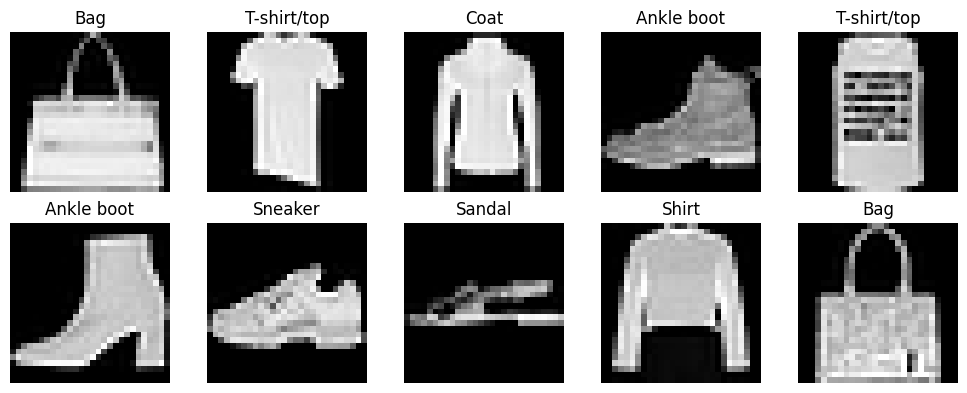

In [ ]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


## 5. Define a small CNN

The first convolution and pooling steps find simple image patterns and reduce the 28 by 28 image to 14 by 14. The second pair reduces it to 7 by 7. The final layers use those learned patterns to choose one of the 10 clothing categories.

The model returns **scores (logits)** for each category. `CrossEntropyLoss` will use those scores and the correct labels during training.


In [ ]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        patterns = self.features(images)
        scores = self.classifier(patterns)
        return scores

model = SmallCNN().to(device)
print(model)


SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 6. Train and evaluate on validation data

**Loss** measures how far the model's scores are from the correct labels; lower is better. **Accuracy** is the fraction of images classified correctly; higher is better. During training, the model updates its weights. During validation, the weights stay unchanged so we can check how it performs on examples it has not learned from.


In [ ]:
def run_one_epoch(model, data_loader, loss_function, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(is_training):
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            scores = model(images)
            loss = loss_function(scores, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = scores.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total
    return average_loss, accuracy

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
}

for epoch in range(num_epochs):
    train_loss, train_accuracy = run_one_epoch(
        model, train_loader, loss_function, optimizer
    )
    validation_loss, validation_accuracy = run_one_epoch(
        model, validation_loader, loss_function
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"train loss: {train_loss:.4f}, train accuracy: {train_accuracy:.3f} | "
        f"validation loss: {validation_loss:.4f}, "
        f"validation accuracy: {validation_accuracy:.3f}"
    )


Epoch 1/5 | train loss: 0.5145, train accuracy: 0.813 | validation loss: 0.3558, validation accuracy: 0.873
Epoch 2/5 | train loss: 0.3270, train accuracy: 0.881 | validation loss: 0.2851, validation accuracy: 0.896
Epoch 3/5 | train loss: 0.2820, train accuracy: 0.897 | validation loss: 0.2724, validation accuracy: 0.900
Epoch 4/5 | train loss: 0.2518, train accuracy: 0.908 | validation loss: 0.2465, validation accuracy: 0.909
Epoch 5/5 | train loss: 0.2264, train accuracy: 0.917 | validation loss: 0.2443, validation accuracy: 0.911


## 7. Plot the learning curves

The curves show how the loss changes as the CNN learns. We will make similar plots for the marker-trained model and compare them.


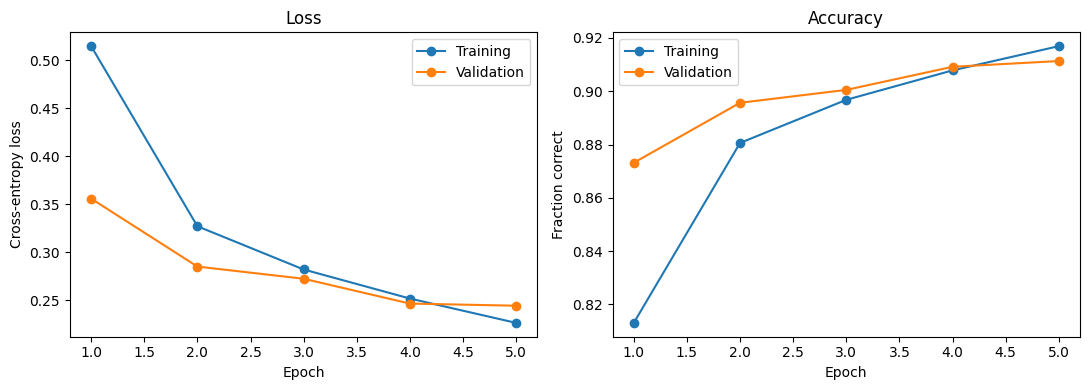

In [ ]:
epochs = range(1, num_epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["validation_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["validation_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Fraction correct")
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Final test-set check

Run this cell after you have chosen the baseline settings using validation results. We will later compare this result with the marker-trained model under the same test conditions.


In [ ]:
test_loss, test_accuracy = run_one_epoch(model, test_loader, loss_function)
print(f"Baseline test loss: {test_loss:.4f}")
print(f"Baseline test accuracy: {test_accuracy:.3f}")


Baseline test loss: 0.2624
Baseline test accuracy: 0.905


## Record this baseline

Save the model and note the settings and final test result. These will be needed for a fair comparison with the marker-trained model.


In [ ]:
torch.save(model.state_dict(), "fashion_mnist_baseline_cnn.pt")

baseline_record = {
    "architecture": "SmallCNN",
    "batch_size": batch_size,
    "learning_rate": 0.001,
    "epochs": num_epochs,
    "seed": seed,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
}
print(baseline_record)


{'architecture': 'SmallCNN', 'batch_size': 64, 'learning_rate': 0.001, 'epochs': 5, 'seed': 42, 'test_loss': 0.2624072629213333, 'test_accuracy': 0.9048}


## What we have so far

- Loaded and viewed the clothing images.
- Created training and validation splits while keeping the test set aside.
- Trained a baseline CNN on unmodified images.
- Recorded loss and accuracy for comparison.

**Next project step:** add the same small, class-linked square to copies of the training images and train the second CNN. Keep the architecture and training settings consistent for a fair comparison.
